# Exploratory Data Analysis (EDA)

### Install Library

In [1]:
pip install -q seaborn

### Import Library

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### Mount Google Drive

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1. Load & Inspect

In [5]:
# Definisi path dataset di Google Drive
DATA_PATH = '/content/drive/MyDrive/Fraud Detection/data/creditcard.csv'

# Load dataset
df = pd.read_csv(DATA_PATH)
print('Dataset berhasil dimuat.')
print()

# Tampilkan 5 baris pertama
print('5 baris pertama dataset:')
print(df.head())

Dataset berhasil dimuat.

5 baris pertama dataset:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.14

In [6]:
# Shape: jumlah baris (transaksi) dan kolom (fitur)
print(f'Jumlah transaksi (baris): {df.shape[0]:,}')
print(f'Jumlah fitur (kolom):    {df.shape[1]}')

Jumlah transaksi (baris): 284,807
Jumlah fitur (kolom):    31


In [7]:
# Informasi umum dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
# Cek missing values pada setiap kolom
missing_count = df.isnull().sum()
total_missing = missing_count.sum()

print(f'Total missing values di seluruh dataset: {total_missing}')

if total_missing > 0:
    missing_df = pd.DataFrame({
        'Missing Count': missing_count[missing_count > 0],
        'Percentage (%)': (missing_count[missing_count > 0] / len(df)) * 100
    })
    print('\nKolom yang memiliki missing values:')
    print(missing_df)
else:
    print('\nTidak ada missing values pada dataset.')

Total missing values di seluruh dataset: 0

Tidak ada missing values pada dataset.


### 2. Class Imbalance Analysis

In [9]:
# Hitung jumlah & proporsi masing-masing kelas
class_counts = df['Class'].value_counts().sort_index()
class_percentage = df['Class'].value_counts(normalize=True).sort_index() * 100

dist_df = pd.DataFrame({
    'Class': ['Legitimate (0)', 'Fraud (1)'],
    'Count': class_counts.values,
    'Percentage (%)': class_percentage.values
})

print('Distribusi kelas:')
print(dist_df.to_string(index=False))
print()
print(f'Fraud rate      : {class_percentage[1]:.4f}% transaksi adalah fraud')
print(f'Imbalance ratio : 1 fraud berbanding {class_counts[0] / class_counts[1]:,.0f} transaksi legitimate')

Distribusi kelas:
         Class  Count  Percentage (%)
Legitimate (0) 284315       99.827251
     Fraud (1)    492        0.172749

Fraud rate      : 0.1727% transaksi adalah fraud
Imbalance ratio : 1 fraud berbanding 578 transaksi legitimate


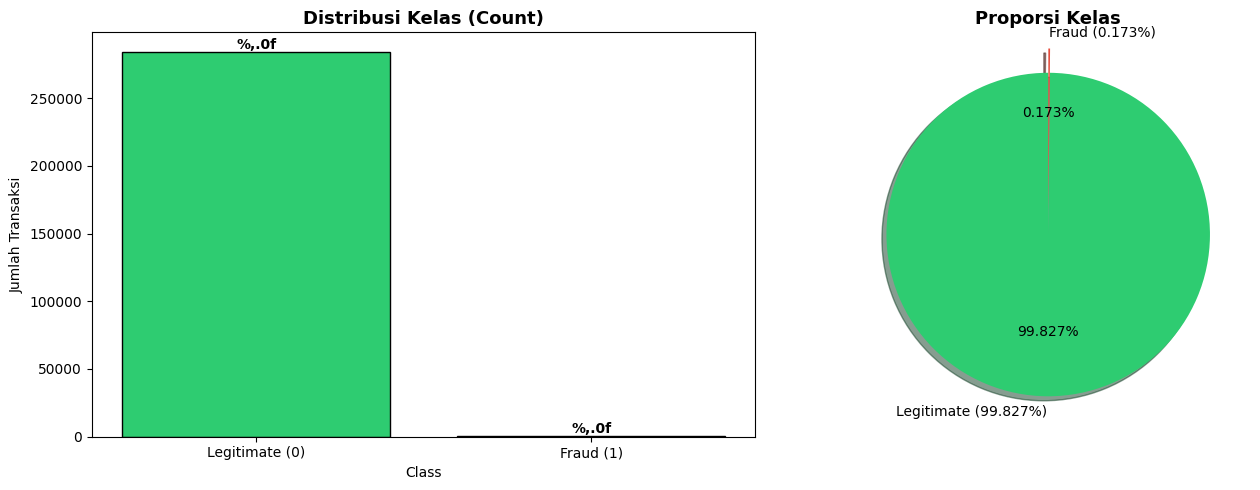

In [10]:
# Visualisasi distribusi kelas: bar chart + pie chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(dist_df['Class'], dist_df['Count'],
                   color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Distribusi Kelas (Count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Jumlah Transaksi')
axes[0].bar_label(bars, fmt='%,.0f', fontweight='bold')

# Pie chart
labels_pie = [f'Legitimate ({class_percentage[0]:.3f}%)', f'Fraud ({class_percentage[1]:.3f}%)']
axes[1].pie(class_counts.values, labels=labels_pie,
            colors=['#2ecc71', '#e74c3c'], autopct='%1.3f%%',
            startangle=90, explode=(0, 0.15), shadow=True)
axes[1].set_title('Proporsi Kelas', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Feature Analysis

Statistik fitur Amount per kelas:
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87



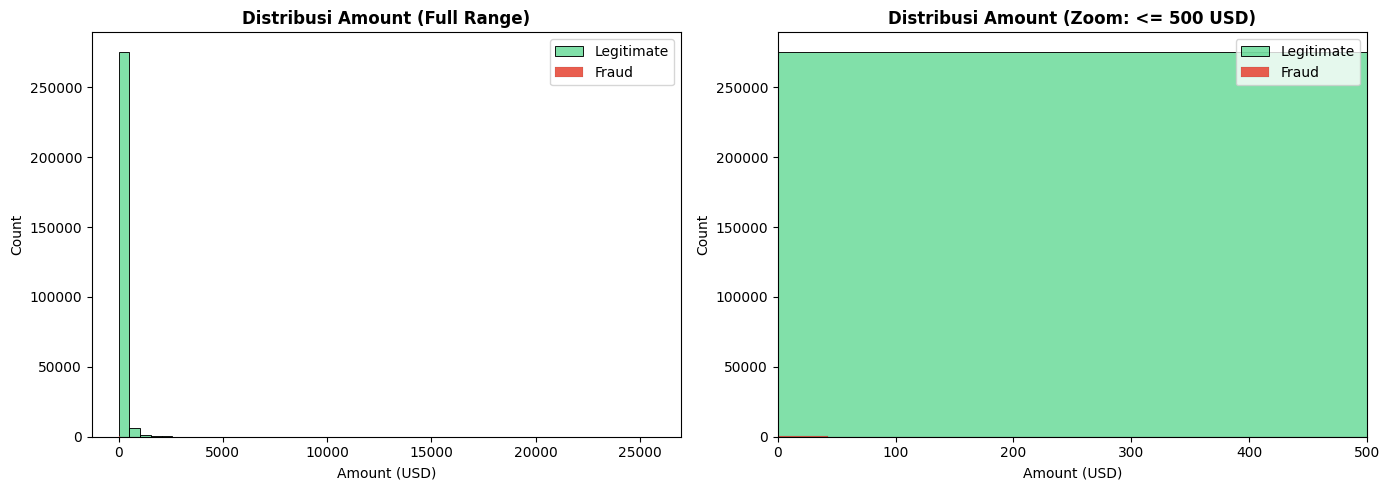

In [11]:
# Statistik deskriptif Amount per kelas
print('Statistik fitur Amount per kelas:')
print(df.groupby('Class')['Amount'].describe().round(2))
print()

# Visualisasi distribusi Amount: fraud vs legitimate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot full range
sns.histplot(x='Amount', data=df[df['Class'] == 0], bins=50, color='#2ecc71',
             alpha=0.6, ax=axes[0], label='Legitimate')
sns.histplot(x='Amount', data=df[df['Class'] == 1], bins=50, color='#e74c3c',
             alpha=0.9, ax=axes[0], label='Fraud')
axes[0].set_title('Distribusi Amount (Full Range)', fontweight='bold')
axes[0].set_xlabel('Amount (USD)')
axes[0].legend()

# Plot zoom untuk amount <= 500 (mayoritas transaksi kecil)
sns.histplot(x='Amount', data=df[df['Class'] == 0], bins=50, color='#2ecc71',
             alpha=0.6, ax=axes[1], label='Legitimate')
sns.histplot(x='Amount', data=df[df['Class'] == 1], bins=50, color='#e74c3c',
             alpha=0.9, ax=axes[1], label='Fraud')
axes[1].set_xlim(0, 500)
axes[1].set_title('Distribusi Amount (Zoom: <= 500 USD)', fontweight='bold')
axes[1].set_xlabel('Amount (USD)')
axes[1].legend()

plt.tight_layout()
plt.show()

Statistik fitur Time per kelas (detik):
          count      mean       std    min      25%      50%       75%  \
Class                                                                    
0      284315.0  94838.20  47484.02    0.0  54230.0  84711.0  139333.0   
1         492.0  80746.81  47835.37  406.0  41241.5  75568.5  128483.0   

            max  
Class            
0      172792.0  
1      170348.0  

Konversi dilakukan: Time_Hour = Time / 3600



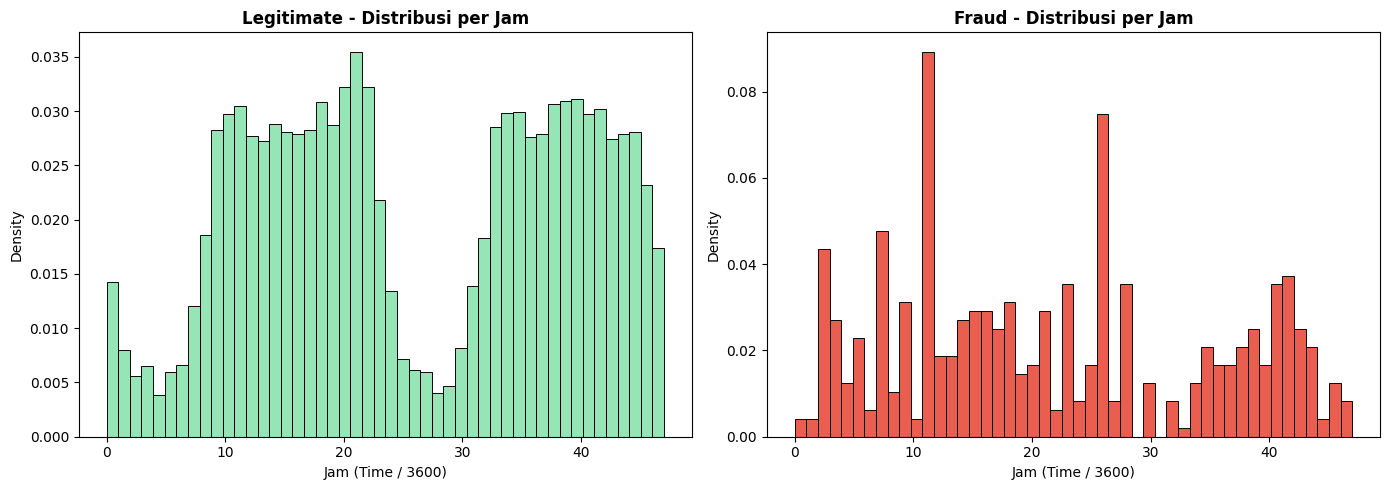

In [12]:
# Statistik deskriptif Time per kelas (Time = detik sejak transaksi pertama)
print('Statistik fitur Time per kelas (detik):')
print(df.groupby('Class')['Time'].describe().round(2))
print()

# Konversi ke jam untuk analisis pola temporal (analisis sementara, bukan fitur permanen)
df['Time_Hour'] = df['Time'] // 3600
print('Konversi dilakukan: Time_Hour = Time / 3600')
print()

# Apakah fraud bersifat time-dependent? Bandingkan distribusi per jam
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(x='Time_Hour', data=df[df['Class'] == 0], bins=48, color='#2ecc71',
             alpha=0.5, ax=axes[0], stat='density')
axes[0].set_title('Legitimate - Distribusi per Jam', fontweight='bold')
axes[0].set_xlabel('Jam (Time / 3600)')
axes[0].set_ylabel('Density')

sns.histplot(x='Time_Hour', data=df[df['Class'] == 1], bins=48, color='#e74c3c',
             alpha=0.9, ax=axes[1], stat='density')
axes[1].set_title('Fraud - Distribusi per Jam', fontweight='bold')
axes[1].set_xlabel('Jam (Time / 3600)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

Jumlah V-features: 28

Ringkasan statistik V1-V28:
     mean    std      min      max
V1    0.0  1.959  -56.408    2.455
V2    0.0  1.651  -72.716   22.058
V3   -0.0  1.516  -48.326    9.383
V4    0.0  1.416   -5.683   16.875
V5    0.0  1.380 -113.743   34.802
V6    0.0  1.332  -26.161   73.302
V7   -0.0  1.237  -43.557  120.589
V8    0.0  1.194  -73.217   20.007
V9   -0.0  1.099  -13.434   15.595
V10   0.0  1.089  -24.588   23.745
V11   0.0  1.021   -4.797   12.019
V12  -0.0  0.999  -18.684    7.848
V13   0.0  0.995   -5.792    7.127
V14   0.0  0.959  -19.214   10.527
V15   0.0  0.915   -4.499    8.878
V16   0.0  0.876  -14.130   17.315
V17  -0.0  0.849  -25.163    9.254
V18   0.0  0.838   -9.499    5.041
V19   0.0  0.814   -7.214    5.592
V20   0.0  0.771  -54.498   39.421
V21   0.0  0.735  -34.830   27.203
V22  -0.0  0.726  -10.933   10.503
V23   0.0  0.624  -44.808   22.528
V24   0.0  0.606   -2.837    4.585
V25   0.0  0.521  -10.295    7.520
V26   0.0  0.482   -2.605    3.517
V27 

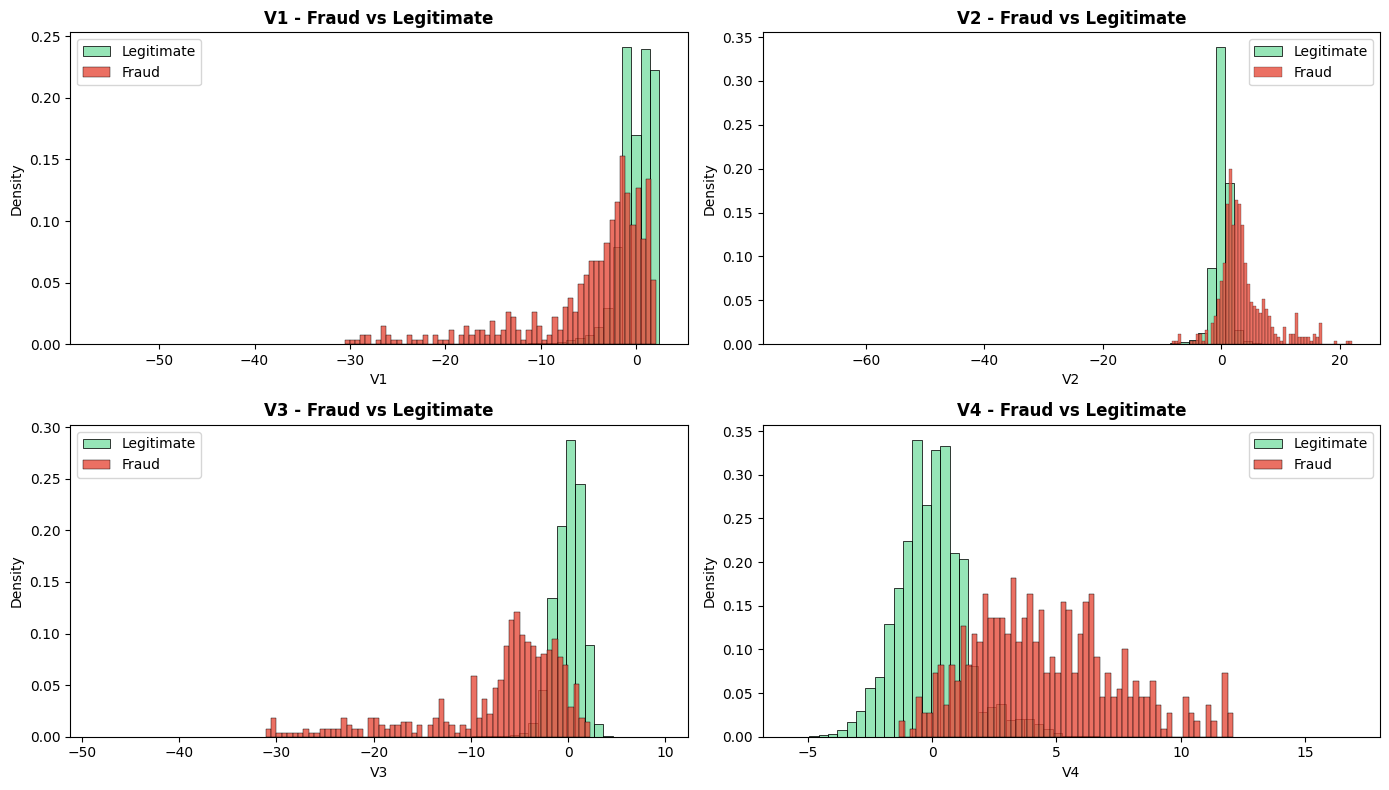

In [13]:
# V1-V28 merupakan fitur PCA yang seharusnya sudah dinormalisasi. Verifikasi:
v_cols = [f'V{i}' for i in range(1, 29)]
print(f'Jumlah V-features: {len(v_cols)}')
print()

# Statistik: mean ~0 dan std ~1 mengindikasikan data sudah dinormalisasi
v_stats = df[v_cols].describe().T[['mean', 'std', 'min', 'max']]
print('Ringkasan statistik V1-V28:')
print(v_stats.round(3).to_string())
print()
print(f'Rata-rata seluruh mean V-features: {v_stats["mean"].mean():.4f}')
print(f'Rata-rata seluruh std  V-features: {v_stats["std"].mean():.4f}')
print()

# Visualisasi contoh: V1-V4 (fraud vs legitimate)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.ravel(), ['V1', 'V2', 'V3', 'V4']):
    sns.histplot(x=col, data=df[df['Class'] == 0], bins=60, color='#2ecc71',
                 alpha=0.5, stat='density', ax=ax, label='Legitimate')
    sns.histplot(x=col, data=df[df['Class'] == 1], bins=60, color='#e74c3c',
                 alpha=0.8, stat='density', ax=ax, label='Fraud')
    ax.set_title(f'{col} - Fraud vs Legitimate', fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()

### 4. Correlation Analysis

In [14]:
# Korelasi seluruh fitur numerik terhadap Class
corr_with_class = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()

# Top 15 fitur dengan |korelasi| terbesar terhadap fraud
top15 = corr_with_class.abs().nlargest(15).index
top15_df = pd.DataFrame({
    'Feature': top15,
    'Correlation': corr_with_class[top15].values
}).sort_values('Correlation', ascending=False)

print('Top 15 fitur paling berkorelasi dengan fraud (Class):')
print(top15_df.to_string(index=False))
print()

# Catatan: nilai korelasi relatif kecil wajar karena fitur merupakan hasil PCA,
# namun tetap menjadi sinyal penting untuk feature importance.

Top 15 fitur paling berkorelasi dengan fraud (Class):
Feature  Correlation
    V11     0.154876
     V4     0.133447
     V2     0.091289
     V6    -0.043643
     V5    -0.094974
     V9    -0.097733
     V1    -0.101347
    V18    -0.111485
     V7    -0.187257
     V3    -0.192961
    V16    -0.196539
    V10    -0.216883
    V12    -0.260593
    V14    -0.302544
    V17    -0.326481



In [17]:
# Cek multikolinearitas antar V-features
corr_matrix = df[v_cols].corr()

# Ambil pasangan dengan korelasi tinggi (threshold 0.7)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = upper_tri.stack().reset_index(name='corr')
high_corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'].abs() >= 0.7]\
    .sort_values('Correlation', key=abs, ascending=False)

print(f'Pasangan V-features dengan |korelasi| >= 0.7: {len(high_corr_pairs)}')
if len(high_corr_pairs) > 0:
    print(high_corr_pairs.to_string(index=False))
else:
    print('Tidak ada pasangan berkorelasi tinggi.')

Pasangan V-features dengan |korelasi| >= 0.7: 0
Tidak ada pasangan berkorelasi tinggi.


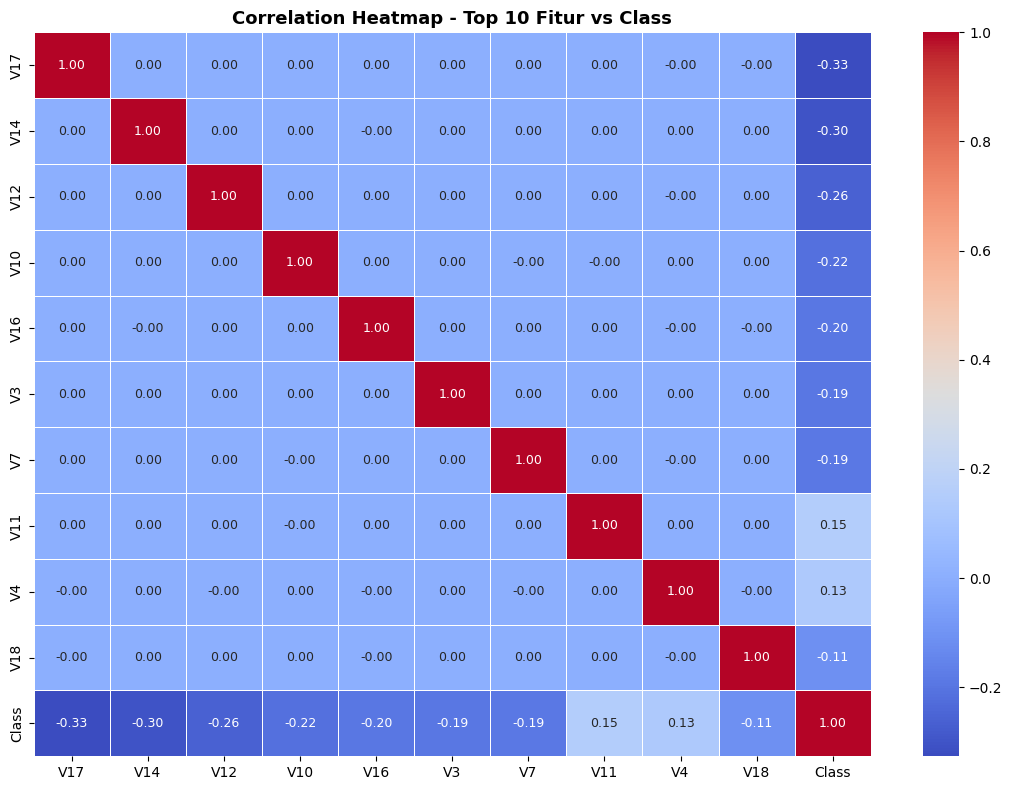

In [18]:
# Heatmap korelasi untuk top 10 fitur + Class
top10 = corr_with_class.abs().nlargest(10).index.tolist()
heat_cols = top10 + ['Class']

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            annot_kws={'size': 9}, linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap - Top 10 Fitur vs Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 5. Fraud Characteristics Summary

In [19]:
# Ringkasan karakteristik fraud vs legitimate
legit = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

summary = pd.DataFrame({
    'Metric': [
        'Total Transactions', 'Fraud Transactions', 'Legit Transactions',
        'Fraud Rate (%)',
        'Avg Amount (Legit)', 'Avg Amount (Fraud)',
        'Median Amount (Legit)', 'Median Amount (Fraud)',
        'Avg Time (Legit)', 'Avg Time (Fraud)'
    ],
    'Value': [
        f"{len(df):,}",
        f"{len(fraud):,}",
        f"{len(legit):,}",
        f"{class_percentage[1]:.4f}",
        f"${legit['Amount'].mean():.2f}",
        f"${fraud['Amount'].mean():.2f}",
        f"${legit['Amount'].median():.2f}",
        f"${fraud['Amount'].median():.2f}",
        f"{legit['Time'].mean():.2f} detik",
        f"{fraud['Time'].mean():.2f} detik"
    ]
})

print(summary.to_string(index=False))

               Metric          Value
   Total Transactions        284,807
   Fraud Transactions            492
   Legit Transactions        284,315
       Fraud Rate (%)         0.1727
   Avg Amount (Legit)         $88.29
   Avg Amount (Fraud)        $122.21
Median Amount (Legit)         $22.00
Median Amount (Fraud)          $9.25
     Avg Time (Legit) 94838.20 detik
     Avg Time (Fraud) 80746.81 detik
